# Лабораторна робота № 1

## Вхідний аналіз набору даних

**Дисципліна:** Інтелектуальний аналіз та візуалізація даних (СК26)
**Тривалість:** 2 год аудиторно + 3 год самостійної роботи · **Максимальна оцінка:** 4 бали

---

### Мета роботи

Пригадати роботу в Jupyter Notebook, бібліотеці `pandas` та побудову графіків —
і зробити це не на навчальному прикладі, а на реальному файлі, який ніхто не готував
спеціально для вас.

Ця робота виконується **до першої лекції**. Нічого нового знати не потрібно: усе,
що знадобиться, ви вже проходили в попередніх курсах. Усі поняття, яких ви тут
торкнетеся мимохідь, отримають назви й пояснення на лекціях 3 і 4.

### Дані

Файл `20171129_FINAL_FINAL.xlsx`, аркуш `Sheet1` — спостереження космічної погоди
за 28 серпня — 22 вересня 2017 року, зібрані з трьох різних джерел.

Файл видається **як є**, рівно в тому вигляді, у якому його колись вивантажили.
Ніхто не приводив його до ладу, і саме в цьому сенс: справжні дані здебільшого
надходять саме такими.

### Що ви маєте зробити

| Етап | Зміст | Де |
|---|---|---|
| 1 | Розібратися, що взагалі лежить у файлі | аудиторно |
| 2 | Виділити три таблиці й привести їх до робочого вигляду | аудиторно |
| 3 | Скласти паспорт даних: що є, чого бракує, що виглядає дивно | аудиторно |
| 4 | Об'єднати три таблиці в одну | аудиторно |
| 5 | Побудувати п'ять графіків, кожен — відповідь на питання | аудиторно + самостійно |
| 6 | Порівняти два графіки одних і тих самих даних | самостійно |
| 7 | Записати три спостереження про дані | самостійно |
| 8 | Декларація про використання інструментів ШІ | самостійно |

### Що здається

1. Цей файл `.ipynb` із заповненими розв'язками. **Ноутбук має виконуватися згори
   донизу на чистому ядрі** (Kernel → Restart & Run All) без помилок — це перевіряється
   першою дією на захисті.
2. Файл `master_hourly.csv` — об'єднана таблиця з етапу 4.
3. Експорт ноутбука у HTML або PDF.
4. Заповнена декларація (етап 8). Без неї фінальна самоперевірка не проходить.

### Критерії оцінювання

| Бали | Що досягнуто |
|---|---|
| 0 | Дані не опрацьовано, графіки не побудовано або побудовано з грубими помилками |
| 1 | Таблиці прочитано й кілька графіків побудовано, але типи графіків не відповідають даним, дивних значень не помічено |
| 2 | Таблиці розібрано й об'єднано, графіки коректні та підписані, але висновків під ними немає або вони формальні |
| 4 | Усе вище виконано, знайдено й пояснено дивні значення, під кожним графіком є змістовний висновок про дані |

**Головне про оцінку:** бали ставляться не за наявність графіка, а за речення під ним.
Код, який нічого не пояснює, коштує двох балів з чотирьох.

---
## Нагадування про Jupyter

Якщо давно не працювали — три речі, які знадобляться сьогодні:

* `Shift+Enter` виконує клітинку, `Esc` `A` / `Esc` `B` додає клітинку вище / нижче,
  `Esc` `M` перетворює клітинку на текстову (Markdown), `Esc` `Y` — назад на код.
* **Порядок виконання має значення.** Якщо ви правили клітинки в довільному порядку,
  результат може залежати від історії запусків. Перед здачею обов'язково
  **Kernel → Restart & Run All** — так ви побачите ноутбук очима викладача.
* Текстові клітинки — не прикраса. Висновки пишуться в них, а не в коментарях до коду.

---
## Крок 0. Ваші дані та варіант

Заповніть три змінні й виконайте обидві клітинки. Друга надрукує **ваше
індивідуальне завдання** — воно відрізняється від завдання сусіда.

In [1]:
ПІБ = 'Мурашко Владислав Сергійович'        # напр. 'Шевченко Тарас'
ГРУПА = 'ШІ-34'      # напр. 'КН-31'
ВАРІАНТ = 10     # ваш номер за списком групи

assert ПІБ and ГРУПА and ВАРІАНТ, 'Заповніть ПІБ, ГРУПУ та ВАРІАНТ'

In [2]:
# --- клітинку не редагувати: вона видає ваше персональне завдання ------------
ПОТОКИ = ['P>1', 'P>5', 'P>10', 'P>30', 'P>50', 'P>100', 'E>0.8', 'E>2.0']

ПАРИ = [('швидкість вітру', 'густина вітру'),
        ('швидкість вітру', 'потік P>10'),
        ('густина вітру', 'потік P>1'),
        ('радіопотік F10.7', 'потік P>10'),
        ('радіопотік F10.7', 'швидкість вітру'),
        ('потік E>0.8', 'потік P>10')]

АГРЕГАТИ = ['середнє', 'максимум', 'медіана', 'мінімум']

ПИТАННЯ = [
    'Скільки годин за все вікно ваш потік перевищував своє власне медіанне значення?',
    'У яку добу середнє значення вашого потоку було найбільшим? А найменшим?',
    'О котрій годині доби потік E>0.8 у середньому найбільший? Побудуйте графік середнього за годинами доби.',
    'Яка частка рядків об’єднаної таблиці має пропуск хоча б в одному стовпці?',
    'У який день радіопотік F10.7 був найбільшим і чи збігається цей день з піком вашого потоку?',
    'Порівняйте медіану вашого потоку за перший і за другий тиждень спостережень. У скільки разів вони відрізняються?',
    'Скільки годин поспіль тривала найдовша неперервна серія «активних» годин (група з етапу 4)?',
    'Який зі стовпців об’єднаної таблиці має найбільший розкид відносно власного середнього?',
    'Яку частку сумарного значення вашого потоку за все вікно дали 24 години навколо піку?',
    'Скільки різних діб потрапило у групу «активні» і скільки — у групу «дуже активні»?',
]

i = int(ВАРІАНТ)
завдання = {
    'ваш потік':                      ПОТОКИ[(i * 3 + 1) % 8],
    'ваша пара для графіка 3':        ' та '.join(ПАРИ[(i * 5 + 2) % 6]),
    'ваш агрегат для етапу 4':        АГРЕГАТИ[(i * 5 + 1) % 4],
    'ваше додаткове питання':         ПИТАННЯ[(i * 11 + 5) % 10],
}

print('ІНДИВІДУАЛЬНЕ ЗАВДАННЯ · %s, %s, варіант %d' % (ПІБ, ГРУПА, i))
print('=' * 78)
for k, v in завдання.items():
    print('%-28s %s' % (k + ':', v))

ІНДИВІДУАЛЬНЕ ЗАВДАННЯ · Мурашко Владислав Сергійович, ШІ-34, варіант 10
ваш потік:                   E>2.0
ваша пара для графіка 3:     радіопотік F10.7 та швидкість вітру
ваш агрегат для етапу 4:     мінімум
ваше додаткове питання:      Порівняйте медіану вашого потоку за перший і за другий тиждень спостережень. У скільки разів вони відрізняються?


Далі за текстом **«ваш потік»** означає стовпець, названий у першому рядку завдання.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 9})

ФАЙЛ = '20171129_FINAL_FINAL.xlsx'

---
# Етап 1. Що взагалі лежить у файлі

Перше правило роботи з незнайомими даними: спершу подивитися, потім рахувати.

### Завдання 1.1
Спробуйте прочитати аркуш `Sheet1` звичайним способом — `pd.read_excel(ФАЙЛ)` —
і виведіть перші рядки та типи стовпців.

*Очікуваний результат: результат буде дивним. Подивіться на назви стовпців і на
те, які там типи даних. Поясніть у наступній клітинці, чому так вийшло.*

In [4]:
df = pd.read_excel(ФАЙЛ)

display(df.head())
display(df.dtypes)

,Unnamed: 0,ftp://ftp.swpc.noaa.gov/pub/lists/particle/,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25,http://umtof.umd.edu/pm/crn/,Unnamed: 27,Unnamed: 28,Unnamed: 29,Unnamed: 30,Unnamed: 31
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,:Data_list: 20170901_Gs_part_5m.txt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,SOHO CELIAS Proton Monitor,NaN,NaN,NaN,NaN,NaN
2,NaN,:Created: 2017 Sep 02 0011 UTC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Solar Wind Parameters for Carrington Rotation ...,NaN,NaN,NaN,NaN,NaN
3,NaN,"# Prepared by the U.S. Dept. of Commerce, NOAA...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Proton speed [km/sec],NaN,NaN,NaN,NaN,NaN
4,NaN,# Please send comments and suggestions to SWPC...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Proton density [protons per cubic centimeter],NaN,NaN,NaN,NaN,NaN


Unnamed: 0                                     float64
ftp://ftp.swpc.noaa.gov/pub/lists/particle/     object
Unnamed: 2                                      object
Unnamed: 3                                      object
Unnamed: 4                                      object
Unnamed: 5                                      object
Unnamed: 6                                      object
Unnamed: 7                                      object
Unnamed: 8                                      object
Unnamed: 9                                      object
Unnamed: 10                                     object
Unnamed: 11                                     object
Unnamed: 12                                     object
Unnamed: 13                                     object
Unnamed: 14                                     object
Unnamed: 15                                    float64
Unnamed: 16                                     object
Unnamed: 17                                     object
Unnamed: 1

**Відповідь 1.1:** Після читання Excel-файлу звичайним способом за допомогою `pd.read_excel()` отримано таблицю з 32 стовпцями. Назви більшості стовпців мають вигляд Unnamed: 2, Unnamed: 3 тощо, а деякі назви містять URL-адреси.

Такий результат пояснюється тим, що вихідний Excel-файл містить не лише самі дані, а й додаткові рядки з описом джерел, заголовками та іншою службовою інформацією. pandas за замовчуванням вважає перший рядок аркуша заголовком таблиці, хоча в цьому файлі він не є правильним рядком із назвами стовпців.

Через це назви стовпців визначаються неправильно, а частина даних зчитується як текстовий тип object. Порожні клітинки перетворюються на NaN, тобто пропущені значення.

Отже, перед подальшим аналізом потрібно дослідити структуру файлу, знайти справжній рядок із заголовками та правильно підготувати дані.

### Завдання 1.2
Прочитайте аркуш ще раз, але **без заголовка**: `pd.read_excel(ФАЙЛ, header=None)`.
Виведіть його розмір і подивіться на перші 30 рядків.

In [5]:
RAW = pd.read_excel(ФАЙЛ, header=None)

print("Розмір таблиці:", RAW.shape)

display(RAW.head(30))


Розмір таблиці: (7226, 32)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31
0,NaN,ftp://ftp.swpc.noaa.gov/pub/lists/particle/,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,http://umtof.umd.edu/pm/crn/,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,:Data_list: 20170901_Gs_part_5m.txt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,SOHO CELIAS Proton Monitor,NaN,NaN,NaN,NaN,NaN
3,NaN,:Created: 2017 Sep 02 0011 UTC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Solar Wind Parameters for Carrington Rotation ...,NaN,NaN,NaN,NaN,NaN
4,NaN,"# Prepared by the U.S. Dept. of Commerce, NOAA...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Proton speed [km/sec],NaN,NaN,NaN,NaN,NaN
5,NaN,# Please send comments and suggestions to SWPC...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Proton density [protons per cubic centimeter],NaN,NaN,NaN,NaN,NaN
6,NaN,#,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,# Label: P > 1 = Particles at >1 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Measurement time (Year, Month, Day of Month, D...",NaN,NaN,NaN,NaN,NaN
8,NaN,# Label: P > 5 = Particles at >5 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,# Label: P >10 = Particles at >10 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Завдання 1.3
Для кожного стовпця порахуйте, скільки в ньому заповнених клітинок
(`RAW.notna().sum()`), і виведіть результат.

*Очікуваний результат: 32 числа. Серед них будуть нулі та згустки великих значень.
За цими згустками видно, що в аркуші **не одна таблиця, а кілька**, вставлені поруч.*

**Питання:** скільки таблиць в аркуші і які стовпці займає кожна?

In [6]:
display(RAW.notna().sum())

0        0
1     7223
2     7202
3     7202
4     7202
5     7203
6     7203
7     7198
8     7198
9     7198
10    7198
11    7198
12    7198
13    7198
14    7198
15       0
16      32
17      26
18      26
19      26
20       0
21       0
22       0
23       0
24     601
25     601
26     608
27     602
28     602
29     602
30     602
31     602
dtype: int64

**Відповідь 1.3:** Судячи з результатів виконання функції `RAW.notna().sum()`, на аркуші знаходиться 3 таблиці:
Перша - стовпці 1-14.
Друга - стовпці 16-19
Третя - стовпці 24-31

### Завдання 1.4
Над кожною таблицею є кілька текстових рядків — це службовий опис від тих, хто дані
збирав. Виведіть їх і випишіть для кожної таблиці **джерело даних та одиниці
вимірювання**.

*Це найкорисніші п'ять хвилин роботи: жодної з цих відомостей у самій таблиці немає,
і без них ви не знатимете, у чому вимірюєте.*

In [7]:
pd.set_option('display.max_colwidth', None)
print('Table 1:')
print(RAW.iloc[:21, 1].dropna().to_string(index=False))
print('Table 2:')
print(RAW.iloc[13:20, 16].dropna().to_string(index=False))
print('Table 3:')
print(RAW.iloc[:8, 26].dropna().to_string(index=False))

Table 1:
                                    ftp://ftp.swpc.noaa.gov/pub/lists/particle/
                                            :Data_list: 20170901_Gs_part_5m.txt
                                                 :Created: 2017 Sep 02 0011 UTC
# Prepared by the U.S. Dept. of Commerce, NOAA, Space Weather Prediction Center
             # Please send comments and suggestions to SWPC.Webmaster@noaa.gov 
                                                                             # 
                                           # Label: P > 1 = Particles at >1 Mev
                                           # Label: P > 5 = Particles at >5 Mev
                                          # Label: P >10 = Particles at >10 Mev
                                          # Label: P >30 = Particles at >30 Mev
                                          # Label: P >50 = Particles at >50 Mev
                                         # Label: P>100 = Particles at >100 Mev
                               

**Відповідь 1.4:**

| Таблиця | Джерело | Одиниці вимірювання |
|---|---|---|
| A |  ftp://ftp.swpc.noaa.gov/pub/lists/particle/ |  Particles = Protons/cm2-s-sr; Electrons = Electrons/cm2-s-sr |
| B |  ftp://ftp.swpc.noaa.gov/pub/indices/old_indices/2017Q3_DSD.txt | - |
| C | http://umtof.umd.edu/pm/crn/ | Proton speed [km/sec]; Proton density [protons per cubic centimeter]|


---
# Етап 2. Три таблиці в робочому вигляді

У файлі три таблиці. Ось що в них лежить — решту ви вже знайшли самі:

| Таблиця | Стовпці аркуша | Що це | Один рядок = |
|---|---|---|---|
| A | B–O | вимірювання із супутника GOES-15: потоки частинок різної енергії | 5 хвилин |
| B | Q–T | добовий показник сонячної активності F10.7 | доба |
| C | Y–AF | швидкість і густина сонячного вітру | година |

### Завдання 2.1
Виділіть кожну таблицю в окремий `DataFrame` — назвіть їх `A`, `B` і `C`.
Дайте стовпцям осмислені назви й перетворіть значення на числа
(`pd.to_numeric(..., errors='coerce')` стане в пригоді).

In [8]:
A = RAW.iloc[26:, 1:15].copy().apply(
    pd.to_numeric, errors="coerce"
)
B = RAW.iloc[27:52, 16:20].copy().apply(
    pd.to_numeric, errors="coerce"
)
C = RAW.iloc[27:628, 24:32].copy().apply(
    pd.to_numeric, errors="coerce"
)

A.columns = [
    "Year",
    "Month",
    "Date",
    "Time_HHMM",
    "Mod_jul_day",
    "Seconds_of_day",
    "P>1",
    "P>5",
    "P>10",
    "P>30",
    "P>50",
    "P>100",
    "E>0.8",
    "E>2"
]

B.columns = [
    "Year",
    "Month",
    "Date",
    "Radio_flux_10.7"
]

C.columns = [
    "Int(copy hour)",
    "Copy hour",
    "Year",
    "Month",
    "Date",
    "Hour",
    "Speed",
    "Density"
]

display(A.head())
display(B.head())
display(len(B))
display(C.head())

,Year,Month,Date,Time_HHMM,Mod_jul_day,Seconds_of_day,P>1,P>5,P>10,P>30,P>50,P>100,E>0.8,E>2
26,2017,8,28,0,57993,0,12.00,0.260,0.180,0.1140,0.1040,0.0793,23600.0,1180.0
27,2017,8,28,5,57993,300,19.40,0.690,0.314,0.1120,0.0612,0.0251,23100.0,1160.0
28,2017,8,28,10,57993,600,8.48,0.168,0.130,0.0717,0.0614,0.0304,22200.0,1090.0
29,2017,8,28,15,57993,900,15.40,0.566,0.198,0.0926,0.0568,0.0251,20400.0,997.0
30,2017,8,28,20,57993,1200,6.41,0.156,0.118,0.0597,0.0494,0.0251,18500.0,875.0


,Year,Month,Date,Radio_flux_10.7
27,2017,8,28,82
28,2017,8,29,84
29,2017,8,30,87
30,2017,8,31,92
31,2017,9,1,93


25

,Int(copy hour),Copy hour,Year,Month,Date,Hour,Speed,Density
27,0.0,0.0,17,8,28,0,285,3.0
28,1.0,1.0,17,8,28,1,305,3.4
29,2.0,2.0,17,8,28,2,309,1.7
30,3.0,3.0,17,8,28,3,304,2.0
31,4.0,4.0,17,8,28,4,302,2.3


### Завдання 2.2
У кожній таблиці дата й час записані **по-різному** й розкидані по кількох стовпцях.
Зберіть для кожної таблиці один стовпець `ts` типу `datetime`.

Після цього обов'язково виведіть для кожної таблиці найранішу й найпізнішу дату.

*Очікуваний результат: усі три таблиці мають лежати в межах серпня–вересня 2017 року.
Якщо у вас вийшов інший рік — придивіться, як записано рік у тій таблиці, і виправте.*

In [9]:
A["ts"] = pd.to_datetime(
    A["Year"].astype(str) + "-" +
    A["Month"].astype(str) + "-" +
    A["Date"].astype(str) + " " +
    A["Time_HHMM"].astype(str).str.zfill(4),
    format="%Y-%m-%d %H%M",
    errors="coerce"
)

B["ts"] = pd.to_datetime(
    B["Year"].astype(str) + "-" +
    B["Month"].astype(str) + "-" +
    B["Date"].astype(str),
    format="%Y-%m-%d",
    errors="coerce"
)

C["ts"] = pd.to_datetime(
    "20" + C["Year"].astype(str) + "-" +
    C["Month"].astype(str) + "-" +
    C["Date"].astype(str) + " " +
    C["Hour"].astype(str),
    format="%Y-%m-%d %H",
    errors="coerce"
)

print("Таблиця A:")
print("Найраніша дата:", A["ts"].min())
print("Найпізніша дата:", A["ts"].max())

print("\nТаблиця B:")
print("Найраніша дата:", B["ts"].min())
print("Найпізніша дата:", B["ts"].max())

print("\nТаблиця C:")
print("Найраніша дата:", C["ts"].min())
print("Найпізніша дата:", C["ts"].max())

Таблиця A:
Найраніша дата: 2017-08-28 00:00:00
Найпізніша дата: 2017-09-21 23:55:00

Таблиця B:
Найраніша дата: 2017-08-28 00:00:00
Найпізніша дата: 2017-09-21 00:00:00

Таблиця C:
Найраніша дата: 2017-08-28 00:00:00
Найпізніша дата: 2017-09-22 00:00:00


**Самоперевірка етапу 2.** Клітинка має виконатися без помилок.

In [10]:
assert len(A) == 7200, 'у таблиці A має бути 7200 рядків, а є %d' % len(A)
assert len(B) == 25,   'у таблиці B має бути 25 рядків, а є %d' % len(B)
assert len(C) == 601,  'у таблиці C має бути 601 рядок, а є %d' % len(C)
for назва, т in [('A', A), ('B', B), ('C', C)]:
    рік = pd.to_datetime(т['ts']).dt.year
    assert рік.min() == 2017 and рік.max() == 2017, 'у таблиці %s рік не 2017 — перевірте збирання дати' % назва
print('Етап 2 пройдено')

Етап 2 пройдено


---
# Етап 3. Паспорт даних

### Завдання 3.1
Для кожної таблиці виведіть: розмір, типи стовпців, кількість пропусків у кожному
стовпці, кількість повних дублікатів рядків і описові статистики (`describe()`).

In [11]:
for name, df in {"A": A, "B": B, "C": C}.items():
    print(f"\n{'='*20} {name} {'='*20}")
    print("Розмір:", df.shape)
    print("\nТипи стовпців:")
    print(df.dtypes)
    print("\nКількість пропусків:")
    print(df.isna().sum())
    print("\nКількість повних дублікатів:", df.duplicated().sum())
    print("\nОписові статистики:")
    display(df.describe())



==================== A ====================
Розмір: (7200, 15)

Типи стовпців:
Year                       int64
Month                      int64
Date                       int64
Time_HHMM                  int64
Mod_jul_day                int64
Seconds_of_day             int64
P>1                      float64
P>5                      float64
P>10                     float64
P>30                     float64
P>50                     float64
P>100                    float64
E>0.8                    float64
E>2                      float64
ts                datetime64[us]
dtype: object

Кількість пропусків:
Year              0
Month             0
Date              0
Time_HHMM         0
Mod_jul_day       0
Seconds_of_day    0
P>1               3
P>5               3
P>10              3
P>30              3
P>50              3
P>100             3
E>0.8             3
E>2               3
ts                0
dtype: int64

Кількість повних дублікатів: 0

Описові статистики:


,Year,Month,Date,Time_HHMM,Mod_jul_day,Seconds_of_day,P>1,P>5,P>10,P>30,P>50,P>100,E>0.8,E>2,ts
count,7200.0,7200.000000,7200.000000,7200.000000,7200.000000,7200.000000,7197.000000,7197.000000,7197.000000,7197.000000,7197.000000,7197.00000,7197.000000,7197.000000,7200
mean,2017.0,8.840000,13.960000,1177.500000,58005.000000,43050.000000,689.325064,156.626057,76.474020,18.838604,7.446840,1.65929,81862.741801,11401.502123,2017-09-09 11:57:30
min,2017.0,8.000000,1.000000,0.000000,57993.000000,0.000000,0.429000,0.151000,0.117000,0.057600,0.045500,0.02240,4.300000,0.133000,2017-08-28 00:00:00
25%,2017.0,9.000000,7.000000,588.750000,57999.000000,21525.000000,11.700000,0.279000,0.186000,0.098400,0.059700,0.02630,22200.000000,552.000000,2017-09-03 05:58:45
50%,2017.0,9.000000,13.000000,1177.500000,58005.000000,43050.000000,55.400000,0.632000,0.376000,0.146000,0.086600,0.03630,68600.000000,4290.000000,2017-09-09 11:57:30
75%,2017.0,9.000000,19.000000,1766.250000,58011.000000,64575.000000,560.000000,107.000000,35.800000,0.990000,0.249000,0.06700,143000.000000,14100.000000,2017-09-15 17:56:15
max,2017.0,9.000000,31.000000,2355.000000,58017.000000,86100.000000,32500.000000,2890.000000,1330.000000,399.000000,191.000000,61.50000,259000.000000,110000.000000,2017-09-21 23:55:00
std,0.0,0.366632,8.775483,692.481902,7.211603,24943.113498,1625.968447,390.921861,222.362627,67.265595,28.620524,7.15889,65728.005824,16920.617446,NaN



==================== B ====================
Розмір: (25, 5)

Типи стовпців:
Year                        int64
Month                       int64
Date                        int64
Radio_flux_10.7             int64
ts                 datetime64[us]
dtype: object

Кількість пропусків:
Year               0
Month              0
Date               0
Radio_flux_10.7    0
ts                 0
dtype: int64

Кількість повних дублікатів: 0

Описові статистики:


,Year,Month,Date,Radio_flux_10.7,ts
count,25.0,25.000000,25.000000,25.000000,25
mean,2017.0,8.840000,13.960000,92.680000,2017-09-09 00:00:00
min,2017.0,8.000000,1.000000,71.000000,2017-08-28 00:00:00
25%,2017.0,9.000000,7.000000,74.000000,2017-09-03 00:00:00
50%,2017.0,9.000000,13.000000,84.000000,2017-09-09 00:00:00
75%,2017.0,9.000000,19.000000,107.000000,2017-09-15 00:00:00
max,2017.0,9.000000,31.000000,140.000000,2017-09-21 00:00:00
std,0.0,0.374166,8.955817,22.206831,NaN



==================== C ====================
Розмір: (601, 9)

Типи стовпців:
Int(copy hour)           float64
Copy hour                float64
Year                       int64
Month                      int64
Date                       int64
Hour                       int64
Speed                      int64
Density                  float64
ts                datetime64[us]
dtype: object

Кількість пропусків:
Int(copy hour)    0
Copy hour         0
Year              0
Month             0
Date              0
Hour              0
Speed             0
Density           0
ts                0
dtype: int64

Кількість повних дублікатів: 0

Описові статистики:


,Int(copy hour),Copy hour,Year,Month,Date,Hour,Speed,Density,ts
count,601.000000,601.000000,601.0,601.000000,601.000000,601.000000,601.000000,601.000000,601
mean,11.480865,11.480865,17.0,8.840266,13.973378,11.480865,506.547421,2.907654,2017-09-09 12:00:00
min,0.000000,0.000000,17.0,8.000000,1.000000,0.000000,-1.000000,-1.000000,2017-08-28 00:00:00
25%,5.000000,5.000000,17.0,9.000000,7.000000,5.000000,447.000000,1.800000,2017-09-03 06:00:00
50%,11.000000,11.000000,17.0,9.000000,13.000000,11.000000,517.000000,2.400000,2017-09-09 12:00:00
75%,17.000000,17.000000,17.0,9.000000,19.000000,17.000000,584.000000,3.400000,2017-09-15 18:00:00
max,23.000000,23.000000,17.0,9.000000,31.000000,23.000000,806.000000,31.700000,2017-09-22 00:00:00
std,6.938063,6.938063,0.0,0.366664,8.781000,6.938063,125.073291,2.637873,NaN


### Завдання 3.2 — дивні значення
Подивіться на рядок `min` у таблиці `describe()` для таблиці C.

Швидкість і густина — фізичні величини, які **не можуть бути від'ємними**.
Знайдіть від'ємні значення, порахуйте, скільки їх, і поверніться до службового опису
з завдання 1.4: там написано, що вони означають.

Замініть ці значення на `NaN` і покажіть, як після цього змінилися середнє й мінімум.

*Очікуваний результат: два числа «до» і «після» для кожного зі стовпців.*

In [12]:
negative_speed = C.loc[C["Speed"] < 0, "Speed"]
negative_density = C.loc[C["Density"] < 0, "Density"]

print("Від'ємні значення Speed:")
print(negative_speed)
print("Кількість:", len(negative_speed))

print("\nВід'ємні значення Density:")
print(negative_density)
print("Кількість:", len(negative_density))


before = {
    "Speed_mean": C["Speed"].mean(),
    "Speed_min": C["Speed"].min(),
    "Density_mean": C["Density"].mean(),
    "Density_min": C["Density"].min()
}


C.loc[C["Speed"] < 0, "Speed"] = np.nan
C.loc[C["Density"] < 0, "Density"] = np.nan


after = {
    "Speed_mean": C["Speed"].mean(),
    "Speed_min": C["Speed"].min(),
    "Density_mean": C["Density"].mean(),
    "Density_min": C["Density"].min()
}


print("\n--- Результат ---")

print(f"Speed:")
print(f"  mean: {before['Speed_mean']} -> {after['Speed_mean']}")
print(f"  min : {before['Speed_min']} -> {after['Speed_min']}")

print(f"\nDensity:")
print(f"  mean: {before['Density_mean']} -> {after['Density_mean']}")
print(f"  min : {before['Density_min']} -> {after['Density_min']}")

Від'ємні значення Speed:
202   -1
203   -1
204   -1
205   -1
206   -1
207   -1
208   -1
209   -1
Name: Speed, dtype: int64
Кількість: 8

Від'ємні значення Density:
202   -1.0
203   -1.0
204   -1.0
205   -1.0
206   -1.0
207   -1.0
208   -1.0
209   -1.0
Name: Density, dtype: float64
Кількість: 8

--- Результат ---
Speed:
  mean: 506.5474209650582 -> 513.3946037099494
  min : -1 -> 277.0

Density:
  mean: 2.9076539101497505 -> 2.960370994940978
  min : -1.0 -> 0.1


**Відповідь 3.2:** У стовпцях Speed та Density було знайдено по 8 від'ємних значень, причому всі вони дорівнюють -1. Оскільки швидкість і густина не можуть бути від'ємними, ці значення не можна трактувати як реальні фізичні вимірювання. Наданий службовий опис підтверджує фізичний зміст цих стовпців, але безпосередньо не пояснює код -1. Він може означати як відповідність некоректним/службовим значенням, так і пропущенні вимірювання.

Після заміни -1 на NaN середня швидкість змінилася з 506.5474 на 513.3946 км/с, а середня густина — з 2.90765 на 2.96037 протонів/см³. Отже, значення -1 занижували середні значення. Мінімум після очищення став фізично осмисленим: 277 км/с для швидкості та 0.1 протонів/см³ для густини.

### Завдання 3.3 — питання на подумати
У таблиці A є стовпці, для яких `describe()` слухняно рахує середнє й стандартне
відхилення, хоча ці числа не мають жодного сенсу.

Знайдіть їх і поясніть своїми словами, чому середнє для них безглузде.

*Підказка: не кожне число в таблиці є результатом вимірювання.*

> Це питання не має однієї «правильної» відповіді з підручника — на нього ви
> відповідаєте з власного здорового глузду. Формальне пояснення буде на лекції 3.

In [13]:
display(A.describe())


,Year,Month,Date,Time_HHMM,Mod_jul_day,Seconds_of_day,P>1,P>5,P>10,P>30,P>50,P>100,E>0.8,E>2,ts
count,7200.0,7200.000000,7200.000000,7200.000000,7200.000000,7200.000000,7197.000000,7197.000000,7197.000000,7197.000000,7197.000000,7197.00000,7197.000000,7197.000000,7200
mean,2017.0,8.840000,13.960000,1177.500000,58005.000000,43050.000000,689.325064,156.626057,76.474020,18.838604,7.446840,1.65929,81862.741801,11401.502123,2017-09-09 11:57:30
min,2017.0,8.000000,1.000000,0.000000,57993.000000,0.000000,0.429000,0.151000,0.117000,0.057600,0.045500,0.02240,4.300000,0.133000,2017-08-28 00:00:00
25%,2017.0,9.000000,7.000000,588.750000,57999.000000,21525.000000,11.700000,0.279000,0.186000,0.098400,0.059700,0.02630,22200.000000,552.000000,2017-09-03 05:58:45
50%,2017.0,9.000000,13.000000,1177.500000,58005.000000,43050.000000,55.400000,0.632000,0.376000,0.146000,0.086600,0.03630,68600.000000,4290.000000,2017-09-09 11:57:30
75%,2017.0,9.000000,19.000000,1766.250000,58011.000000,64575.000000,560.000000,107.000000,35.800000,0.990000,0.249000,0.06700,143000.000000,14100.000000,2017-09-15 17:56:15
max,2017.0,9.000000,31.000000,2355.000000,58017.000000,86100.000000,32500.000000,2890.000000,1330.000000,399.000000,191.000000,61.50000,259000.000000,110000.000000,2017-09-21 23:55:00
std,0.0,0.366632,8.775483,692.481902,7.211603,24943.113498,1625.968447,390.921861,222.362627,67.265595,28.620524,7.15889,65728.005824,16920.617446,NaN


**Відповідь 3.3:** У таблиці A describe() рахує статистики для всіх числових стовпців, але не всі ці числа є результатами вимірювань. Зокрема, Year, Month, Date, Time_HHMM, Mod_jul_day і Seconds_of_day є компонентами дати/часу або службовими часовими індексами. Тому їхнє середнє та стандартне відхилення не мають такого змісту, як для фізичних величин. Наприклад, середній Month або Date не є фізичною характеристикою, а Time_HHMM взагалі не є звичайною числовою шкалою: значення 0930 означає 09:30, а не число 930 у фізичному сенсі. describe() цього не знає і просто виконує арифметичні операції над числами.

---
# Етап 4. Об'єднання трьох таблиць в одну

Таблиці мають різний крок у часі: 5 хвилин, година і доба. Щоб працювати з ними
разом, потрібна спільна сітка. Беремо **годину**.

Кожна таблиця потребує своєї дії:

1. **A: 5 хвилин → година.** Кілька рядків згортаються в один — це `resample` + агрегація.
2. **C: уже година.** Просте з'єднання по спільному стовпцю `ts` — `merge`.
3. **B: доба → година.** Навпаки, одне значення розтягується на 24 години доби.

### Завдання 4.1
Зведіть таблицю A до погодинної сітки. Для кожного потоку порахуйте **два** числа
за годину: середнє і максимум.

In [14]:
aggr_cols = [
    "ts",
    "P>1",
    "P>5",
    "P>10",
    "P>30",
    "P>50",
    "P>100",
    "E>0.8",
    "E>2"
]

A_hourly = (
    A[aggr_cols]
     .set_index("ts")
     .sort_index()
     .resample("1h")
     .agg(["mean", "max"])
)

A_hourly.columns = [
    f"{col}_{stat}"
    for col, stat in A_hourly.columns
]

A_hourly = A_hourly.reset_index()

display(A_hourly.head())
print(A_hourly.shape)

,ts,P>1_mean,P>1_max,P>5_mean,P>5_max,P>10_mean,P>10_max,P>30_mean,P>30_max,P>50_mean,P>50_max,P>100_mean,P>100_max,E>0.8_mean,E>0.8_max,E>2_mean,E>2_max
0,2017-08-28 00:00:00,9.778333,19.40,0.324917,0.690,0.192917,0.314,0.098850,0.2240,0.077583,0.1780,0.040692,0.0793,20941.666667,23600.0,1011.583333,1180.0
1,2017-08-28 01:00:00,7.994167,13.60,0.291667,0.512,0.156583,0.259,0.072583,0.0919,0.058700,0.0798,0.029950,0.0471,18091.666667,20600.0,713.000000,907.0
2,2017-08-28 02:00:00,6.099167,10.80,0.283000,0.479,0.177667,0.321,0.084450,0.1210,0.069642,0.1110,0.035025,0.0595,14108.333333,15000.0,380.833333,475.0
3,2017-08-28 03:00:00,4.752500,7.76,0.236833,0.329,0.166333,0.244,0.087658,0.1800,0.068092,0.1390,0.035517,0.0818,12766.666667,13100.0,267.916667,284.0
4,2017-08-28 04:00:00,4.158333,6.62,0.334917,0.539,0.208333,0.309,0.084800,0.1530,0.072850,0.1420,0.039708,0.0694,11333.333333,12300.0,203.000000,234.0


(600, 17)


### Завдання 4.2
У вашому завданні названо агрегат (`середнє`, `максимум`, `медіана` або `мінімум`).

Візьміть ваш потік за одну добу, порахуйте для нього по годинах ваш агрегат і ще один
на ваш вибір, і побудуйте обидві криві на одному графіку.

**Питання:** чим вони відрізняються і в якій ситуації різниця між ними стане суттєвою?

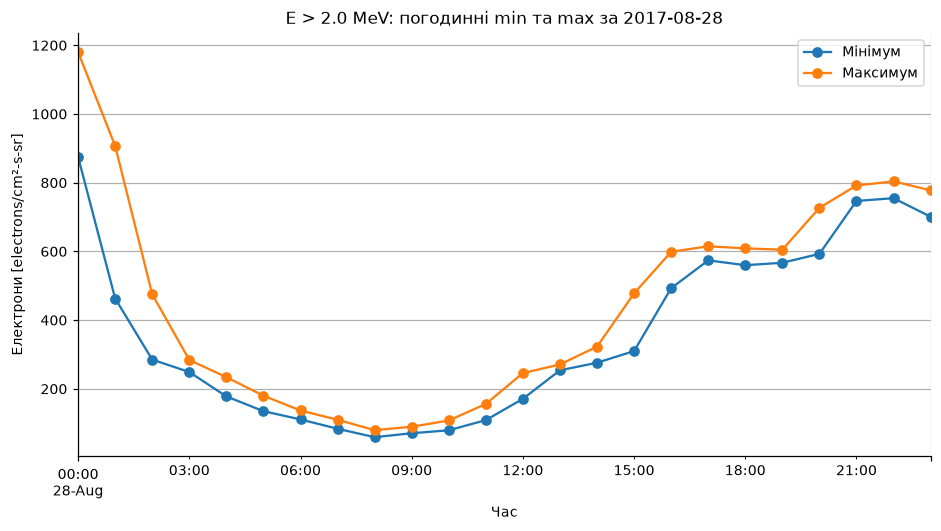

In [15]:
day = A["ts"].dt.date.iloc[0]

A_day = A[A["ts"].dt.date == day].copy()

E2_hourly = (
    A_day.set_index("ts")["E>2"]
    .resample("1h")
    .agg(["min", "max"])
)

E2_hourly.plot(
    y=["min", "max"],
    figsize=(10, 5),
    marker="o"
)

plt.title(f"E > 2.0 MeV: погодинні min та max за {day}")
plt.xlabel("Час")
plt.ylabel("Електрони [electrons/cm²-s-sr]")
plt.legend(["Мінімум", "Максимум"])
plt.grid(True)
plt.show()

**Відповідь 4.2:** Різниця між мінімумом і максимумом є своєрідною ознакою внутрішньогодинної мінливості потоку: чим більша відстань між кривими, тим сильніше значення потоку коливалися протягом цієї години. 
Наприклад, за графіком можна побачити, що за перші 3 години значення потоку коливалися найбільше, а в проміжку між 6:00 та 9:00 коливання були мінімальними.

### Завдання 4.3
Об'єднайте три таблиці в одну — назвіть її `M`. Виведіть її розмір і всі рядки,
у яких є хоча б один пропуск.

**Зверніть увагу:** таблиці закінчуються не в один і той самий момент. Тому результат
залежить від того, який тип об'єднання ви оберете (`how='inner'` чи `how='outer'`).
Спробуйте обидва, подивіться, чим відрізняється кількість рядків, і поясніть свій вибір.

In [16]:
C_hourly = C[
    ["ts", "Speed", "Density"]
].copy()

B_hourly = (
    B[["ts", "Radio_flux_10.7"]]
    .set_index("ts")
    .resample("1h")
    .ffill()
    .reset_index()
)

M_outer = (
    A_hourly
    .merge(B_hourly, on="ts", how="outer")
    .merge(C_hourly, on="ts", how="outer")
    .sort_values("ts")
    .reset_index(drop=True)
)

print("Розмір M_outer:", M_outer.shape)

print("\nРядки, де є хоча б один пропуск:")
display(M_outer[M_outer.isna().any(axis=1)])

M_inner = (
    A_hourly
    .merge(B_hourly, on="ts", how="inner")
    .merge(C_hourly, on="ts", how="inner")
    .sort_values("ts")
    .reset_index(drop=True)
)

print("Розмір M_inner:", M_inner.shape)

print("\nРядки, де є хоча б один пропуск:")
display(M_inner[M_inner.isna().any(axis=1)])

M = M_outer

Розмір M_outer: (601, 20)

Рядки, де є хоча б один пропуск:


,ts,P>1_mean,P>1_max,P>5_mean,P>5_max,P>10_mean,P>10_max,P>30_mean,P>30_max,P>50_mean,P>50_max,P>100_mean,P>100_max,E>0.8_mean,E>0.8_max,E>2_mean,E>2_max,Radio_flux_10.7,Speed,Density
175,2017-09-04 07:00:00,6.465833,10.10,0.262083,0.593,0.171500,0.294,0.085483,0.145,0.068558,0.1340,0.031717,0.0523,90600.000000,100000.0,7410.833333,8950.0,140.0,NaN,NaN
176,2017-09-04 08:00:00,4.010833,5.08,0.256000,0.432,0.195833,0.336,0.086625,0.145,0.070033,0.1340,0.036492,0.0546,73483.333333,79300.0,5048.333333,5850.0,140.0,NaN,NaN
177,2017-09-04 09:00:00,3.268333,4.42,0.303417,0.518,0.220333,0.302,0.105925,0.162,0.081975,0.1340,0.046483,0.0765,60475.000000,68500.0,3715.833333,4480.0,140.0,NaN,NaN
178,2017-09-04 10:00:00,3.179167,4.74,0.252167,0.372,0.181833,0.280,0.101900,0.150,0.081675,0.1200,0.054125,0.0894,64383.333333,68400.0,4122.500000,4710.0,140.0,NaN,NaN
179,2017-09-04 11:00:00,5.274167,7.98,0.295083,0.657,0.186917,0.276,0.089525,0.166,0.063983,0.1100,0.033633,0.0684,79933.333333,88200.0,6345.833333,7430.0,140.0,NaN,NaN
180,2017-09-04 12:00:00,2.965000,4.85,0.217750,0.428,0.153500,0.239,0.089217,0.179,0.071217,0.1440,0.037233,0.0679,80516.666667,88700.0,6080.000000,7420.0,140.0,NaN,NaN
181,2017-09-04 13:00:00,3.061667,3.86,0.275833,0.551,0.192833,0.329,0.104542,0.170,0.083783,0.1590,0.041342,0.0611,76733.333333,85900.0,6015.833333,7540.0,140.0,NaN,NaN
182,2017-09-04 14:00:00,7.279167,10.80,0.231333,0.409,0.170583,0.313,0.086508,0.178,0.070667,0.1660,0.037375,0.0888,83025.000000,90200.0,8552.500000,10500.0,140.0,NaN,NaN
577,2017-09-21 01:00:00,37.408333,56.30,0.268250,0.375,0.196667,0.335,0.116075,0.255,0.078192,0.1600,0.039483,0.0737,159833.333333,164000.0,38200.000000,41400.0,NaN,453.0,1.9
578,2017-09-21 02:00:00,36.841667,48.60,0.357250,0.774,0.229333,0.493,0.100842,0.154,0.071567,0.1290,0.038883,0.0737,150583.333333,158000.0,32333.333333,36000.0,NaN,453.0,1.9


Розмір M_inner: (577, 20)

Рядки, де є хоча б один пропуск:


,ts,P>1_mean,P>1_max,P>5_mean,P>5_max,P>10_mean,P>10_max,P>30_mean,P>30_max,P>50_mean,P>50_max,P>100_mean,P>100_max,E>0.8_mean,E>0.8_max,E>2_mean,E>2_max,Radio_flux_10.7,Speed,Density
175,2017-09-04 07:00:00,6.465833,10.10,0.262083,0.593,0.171500,0.294,0.085483,0.145,0.068558,0.134,0.031717,0.0523,90600.000000,100000.0,7410.833333,8950.0,140,NaN,NaN
176,2017-09-04 08:00:00,4.010833,5.08,0.256000,0.432,0.195833,0.336,0.086625,0.145,0.070033,0.134,0.036492,0.0546,73483.333333,79300.0,5048.333333,5850.0,140,NaN,NaN
177,2017-09-04 09:00:00,3.268333,4.42,0.303417,0.518,0.220333,0.302,0.105925,0.162,0.081975,0.134,0.046483,0.0765,60475.000000,68500.0,3715.833333,4480.0,140,NaN,NaN
178,2017-09-04 10:00:00,3.179167,4.74,0.252167,0.372,0.181833,0.280,0.101900,0.150,0.081675,0.120,0.054125,0.0894,64383.333333,68400.0,4122.500000,4710.0,140,NaN,NaN
179,2017-09-04 11:00:00,5.274167,7.98,0.295083,0.657,0.186917,0.276,0.089525,0.166,0.063983,0.110,0.033633,0.0684,79933.333333,88200.0,6345.833333,7430.0,140,NaN,NaN
180,2017-09-04 12:00:00,2.965000,4.85,0.217750,0.428,0.153500,0.239,0.089217,0.179,0.071217,0.144,0.037233,0.0679,80516.666667,88700.0,6080.000000,7420.0,140,NaN,NaN
181,2017-09-04 13:00:00,3.061667,3.86,0.275833,0.551,0.192833,0.329,0.104542,0.170,0.083783,0.159,0.041342,0.0611,76733.333333,85900.0,6015.833333,7540.0,140,NaN,NaN
182,2017-09-04 14:00:00,7.279167,10.80,0.231333,0.409,0.170583,0.313,0.086508,0.178,0.070667,0.166,0.037375,0.0888,83025.000000,90200.0,8552.500000,10500.0,140,NaN,NaN


**Відповідь 4.3:**
Inner об'єднання дало в результаті 577 рядки, в той час як outer об'єднання призвело до таблиці з 601 рядком. Різниця у кількості рядків якраз полягає в обраному об'єднанні: inner з'єднює рядки тільки тоді, коли для всіх рядків запис з відповідним маркером часу існує. Outer - навпаки, об'єднює рядки коли існує хоча б один запис у відповідний час. 

Для цього завдання я б обрав outer, тому що в умові прямо сказано, що таблиці закінчуються в різний момент, і нас цікавить об'єднана часова шкала без втрати даних.

### Завдання 4.4 — поділ на групи
Щоб далі було що з чим порівнювати, поділіть години на три групи за значенням
**максимуму потоку P>10 за годину**:

| Група | Умова |
|---|---|
| `тиха` | менше 10 |
| `активна` | від 10 до 1000 |
| `дуже активна` | 1000 і більше |

Додайте до `M` стовпець `група` і виведіть, скільки годин потрапило в кожну.

> Це не вигадані числа: саме такі пороги використовує метеослужба космічної погоди
> NOAA. Чому вони саме такі — питання не сьогоднішньої роботи.

In [17]:
M["група"] = np.select(
    [
        M["P>10_max"] < 10,
        M["P>10_max"] < 1000
    ],
    [
        "тиха",
        "активна"
    ],
    default="дуже активна"
)

print(M["група"].value_counts())


група
тиха            411
активна         171
дуже активна     19
Name: count, dtype: int64


**Самоперевірка етапу 4.**

In [18]:
assert M is not None, 'таблиця M не побудована'
assert 'ts' in M.columns, 'у таблиці M потрібен стовпець ts'
assert 'група' in M.columns, 'у таблиці M потрібен стовпець «група»'
assert 590 <= len(M) <= 605, 'очікується близько 600 рядків, а є %d — перевірте об’єднання' % len(M)
print('Етап 4 пройдено:', len(M), 'рядків')

Етап 4 пройдено: 601 рядків


---
# Етап 5. П'ять графіків — п'ять питань

Графік будується як **відповідь на питання**, а не «щоб був».

**Вимоги до кожного графіка:**

* підписані обидві осі, з одиницями вимірювання;
* заголовок;
* під графіком, у текстовій клітинці, — **одне речення про дані**.
  Не «на графіку зображено потік протонів», а твердження на кшталт
  «більшість годин потік не перевищує 60, але кілька годин дають значення у сотні разів більші».

> Не кожне питання має відповідь «так, зв'язок є». Якщо на графіку нічого не видно —
> так і напишіть. Відсутність зв'язку — це теж результат, і чесно про неї написати
> важливіше, ніж підбирати ракурс, у якому «щось наче проглядається».

### Графік 1. Як розподілені значення вашого потоку?
Побудуйте гістограму вашого потоку (середнє за годину). Порахуйте окремо середнє
й медіану цього стовпця.

Якщо гістограма вийде нечитабельною — стовпчик біля нуля і порожньо далі — не
залишайте так. Спробуйте побудувати гістограму від логарифма значень
(`np.log10`) і подивіться, що зміниться.

**Питання:** чому середнє й медіана так сильно відрізняються?

Середнє: 11397.048492310607
Медіана: 4338.75


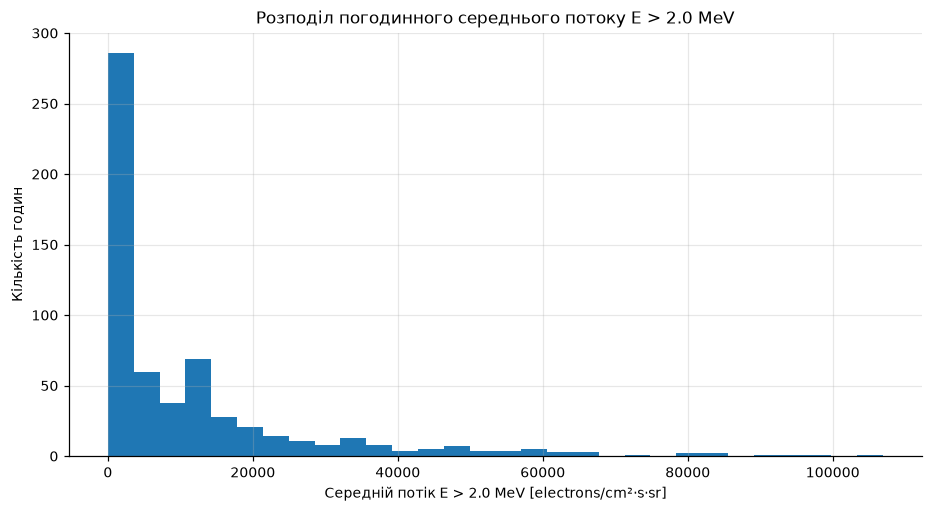

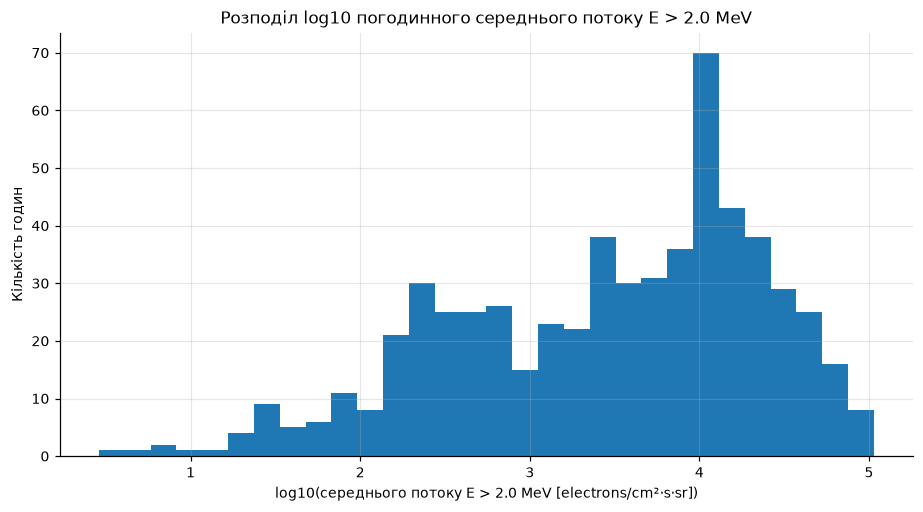

In [19]:
mean_E2 = M["E>2_mean"].mean()
median_E2 = M["E>2_mean"].median()

print("Середнє:", mean_E2)
print("Медіана:", median_E2)

E2 = M["E>2_mean"].dropna()

plt.figure(figsize=(10, 5))

plt.hist(
    E2,
    bins=30
)

plt.xlabel("Середній потік E > 2.0 MeV [electrons/cm²·s·sr]")
plt.ylabel("Кількість годин")
plt.title("Розподіл погодинного середнього потоку E > 2.0 MeV")
plt.grid(True, alpha=0.3)

plt.show()

E2_log = np.log10(E2)

plt.figure(figsize=(10, 5))

plt.hist(
    E2_log,
    bins=30
)

plt.xlabel("log10(середнього потоку E > 2.0 MeV [electrons/cm²·s·sr])")
plt.ylabel("Кількість годин")
plt.title("Розподіл log10 погодинного середнього потоку E > 2.0 MeV")
plt.grid(True, alpha=0.3)

plt.show()


**Висновок:** Більшість годин має відносно невеликий потік E>2.0 MeV, але окремі години характеризуються значно більшими значеннями, через що розподіл має довгий правий хвіст. При спробі побудувати гістограму від логарифму, він стискає великі значення й розтягує область малих значень, тому стає помітнішою структура даних і розподіл уже не виглядає зосередженим лише біля нуля. 
Результати вимірювання середнього та медіани по стовпцю:

Середнє: 11397.048492310607

Медіана: 4338.75

Чому вони так сильно відрізняються? Це теж пов'язано з зосередженням більшості даних біля менших значень.
Медіана — це значення посередині впорядкованого набору даних. Якщо більшість годин має невеликий потік, медіана залишається невеликою.
Середнє враховує величину кожного значення. Тому кілька годин із дуже великим потоком сильно підтягують середнє вгору.

### Графік 2. Чи відрізняється швидкість вітру між групами годин?
Побудуйте діаграму розмаху (`boxplot`) швидкості сонячного вітру окремо для кожної
групи з завдання 4.4.

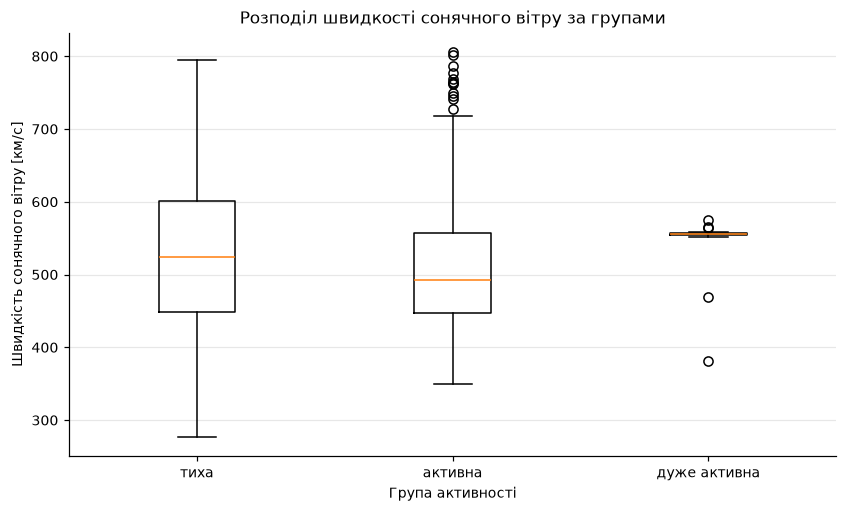

In [20]:
groups = ["тиха", "активна", "дуже активна"]

speed_by_group = [
    M.loc[M["група"] == group, "Speed"].dropna()
    for group in groups
]

plt.figure(figsize=(9, 5))

plt.boxplot(
    speed_by_group,
    tick_labels=groups
)

plt.xlabel("Група активності")
plt.ylabel("Швидкість сонячного вітру [км/с]")
plt.title("Розподіл швидкості сонячного вітру за групами")
plt.grid(True, axis="y", alpha=0.3)

plt.show()

**Висновок:** За графіком можна спостерігати, що розподіл швидкості між точками тихої групи є досить рівномірним, та ми не спостерігаємо жодних точок "викиду". У активної групи ці точкі вже з'являються біля верхньої межі, та медіана швидкості групи є меншою за медіану тихої. У дуже активної групи діаграма сильно відрізняється: більшість значень зосереджені на малому проміжку біля швидкості 550 км/с, з чотирма входженнями, що мають інші показники швидкості.

### Графік 3. Чи пов'язані змінні вашої пари?
Побудуйте діаграму розсіювання для пари з вашого завдання. Порахуйте коефіцієнт
кореляції між ними.

Коефіцієнт кореляції: 0.026930338363450056


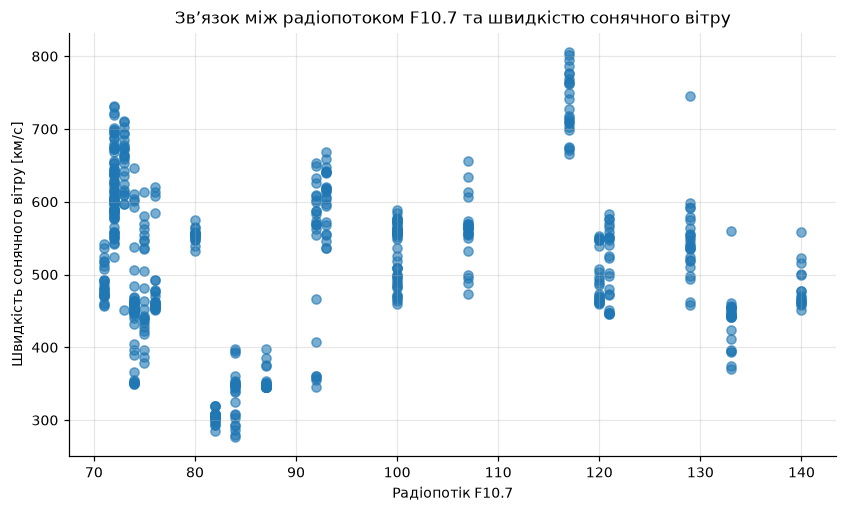

In [21]:
data = M[["Radio_flux_10.7", "Speed"]].dropna()

correlation = data["Radio_flux_10.7"].corr(data["Speed"])

print("Коефіцієнт кореляції:", correlation)

plt.figure(figsize=(9, 5))

plt.scatter(
    data["Radio_flux_10.7"],
    data["Speed"],
    alpha=0.6
)

plt.xlabel("Радіопотік F10.7")
plt.ylabel("Швидкість сонячного вітру [км/с]")
plt.title("Зв’язок між радіопотоком F10.7 та швидкістю сонячного вітру")

plt.grid(True, alpha=0.3)
plt.show()

**Висновок:** Точки не формують чіткої лінійної залежності, а значення коефіцієнта кореляції близьке до нуля (0.027), тому помітного лінійного зв’язку між F10.7 та швидкістю сонячного вітру не виявлено.

### Графік 4. Скільки годин у кожній групі?
Побудуйте стовпчикову діаграму кількості годин за групами. Підпишіть кожен стовпчик
кількістю годин і відсотком від загальної кількості.

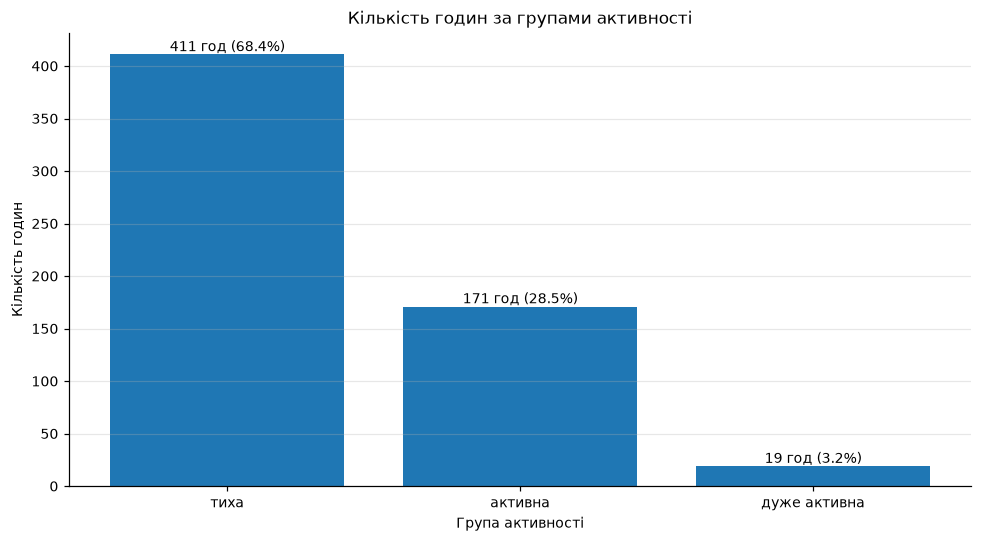

In [22]:
counts = (
    M["група"]
    .value_counts()
    .reindex(groups, fill_value=0)
)

percentages = counts / counts.sum() * 100

plt.figure(figsize=(9, 5))

bars = plt.bar(
    counts.index,
    counts.values
)

plt.xlabel("Група активності")
plt.ylabel("Кількість годин")
plt.title("Кількість годин за групами активності")
plt.grid(True, axis="y", alpha=0.3)

for bar, count, percent in zip(
    bars,
    counts.values,
    percentages.values
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count} год ({percent:.1f}%)",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

**Висновок:** За діаграмою можна побачити, що більшість часу спостерігається тиха активність (68.4%), активні та дуже активні групи були серед 28.5% та 3.2% записів відповідно.

### Графік 5. Як усе це виглядало в часі?
Побудуйте лінійний графік максимуму потоку P>10 за годину за весь період спостережень.

Якщо крива виявиться нечитабельною — згадайте, що допомогло в графіку 1.

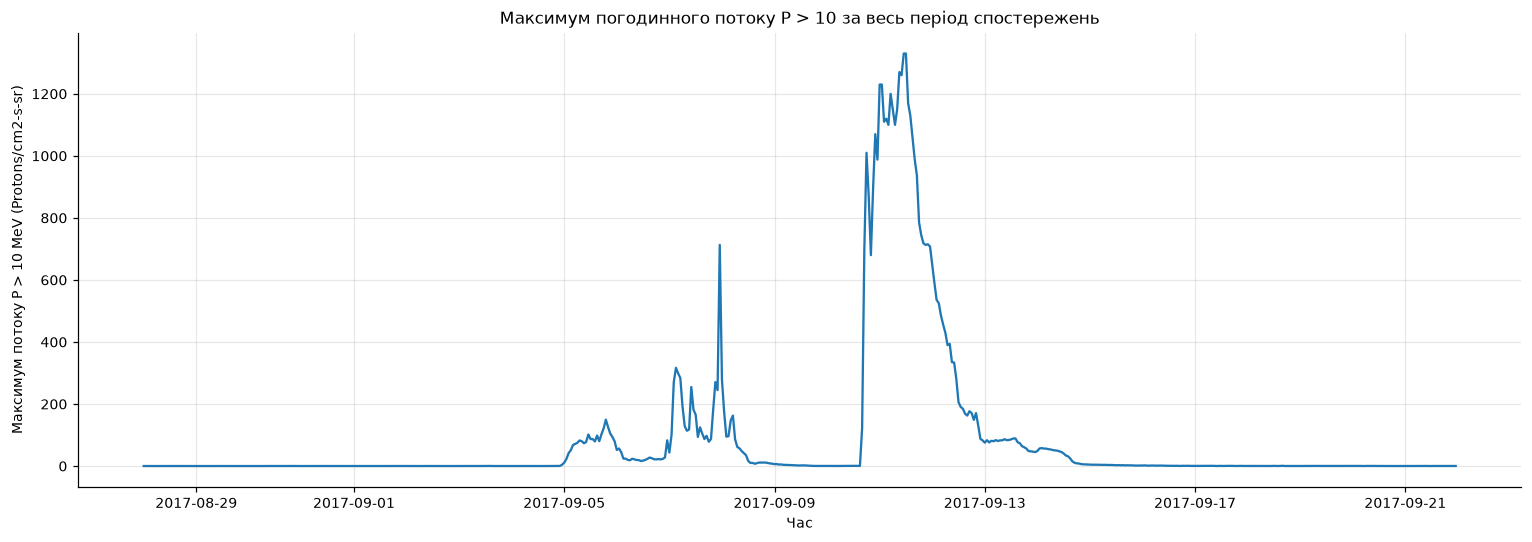

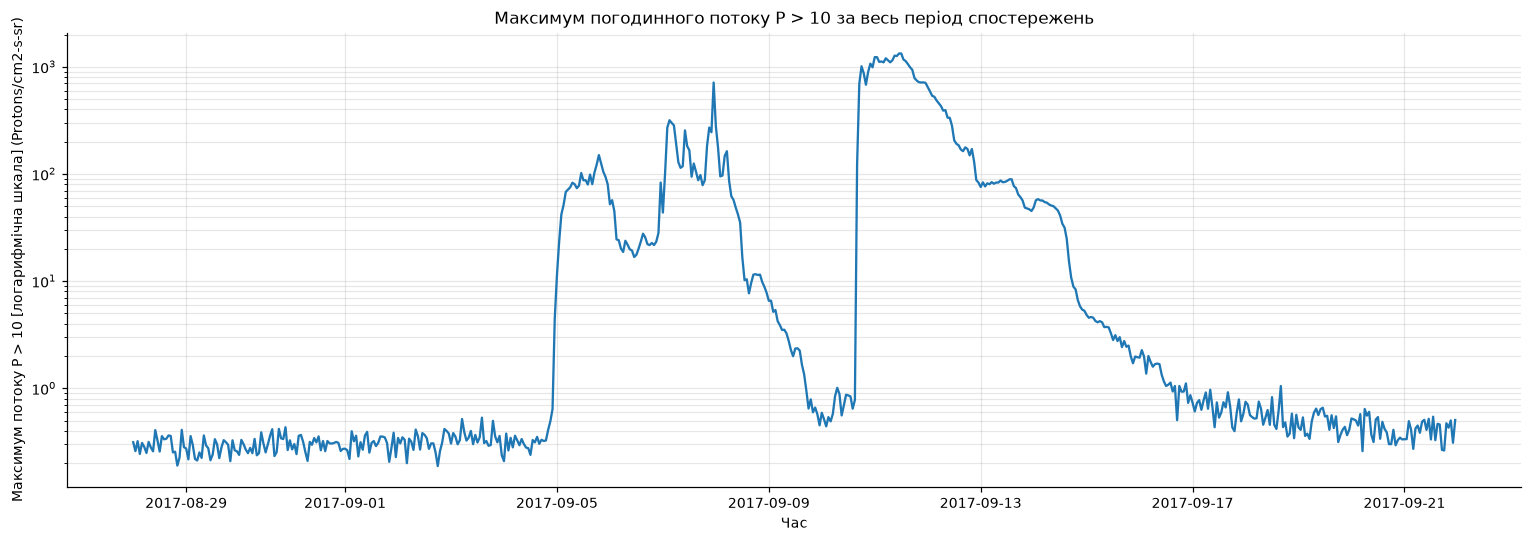

In [23]:
data = M[["ts", "P>10_max"]].dropna()

plt.figure(figsize=(14, 5))

plt.plot(
    data["ts"],
    data["P>10_max"]
)

plt.xlabel("Час")
plt.ylabel("Максимум потоку P > 10 MeV (Protons/cm2-s-sr)")
plt.title("Максимум погодинного потоку P > 10 за весь період спостережень")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 5))

plt.plot(
    data["ts"],
    data["P>10_max"]
)

plt.yscale("log")

plt.xlabel("Час")
plt.ylabel("Максимум потоку P > 10 [логарифмічна шкала] (Protons/cm2-s-sr)")
plt.title("Максимум погодинного потоку P > 10 за весь період спостережень")
plt.grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.show()


**Висновок:** За графіком можна побачити, що найбільший максимальний потік протонів за P>10 спостерігався з 09.11 до 09.13 числа, після чого поступово спадав. Також підвищена активність помічена з 09.05 до 09.08.

---
# Етап 6. Два графіки одних і тих самих даних

Нижче побудовано два графіки. Дані в них **одні й ті самі** — це той самий стовпець
з тієї самої таблиці, жодне число не змінено.

Виконайте клітинку й подивіться на обидва.

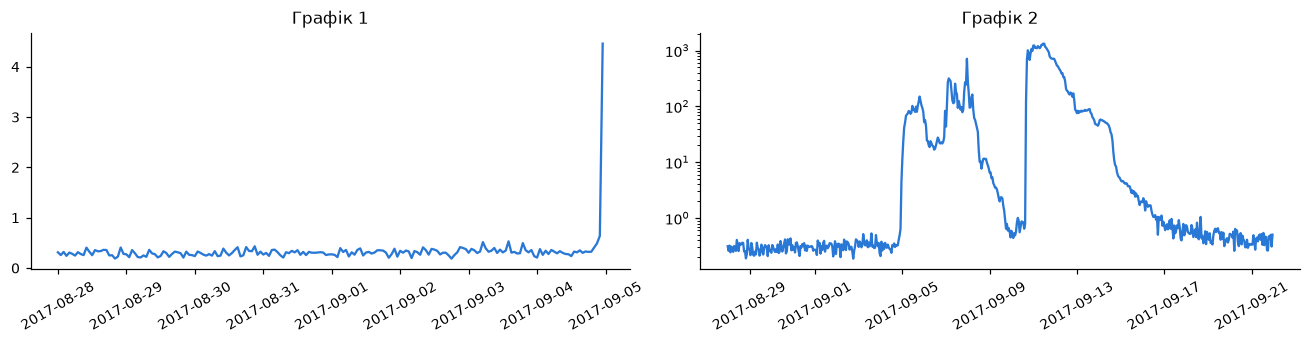

In [24]:
СТОВПЕЦЬ = 'P>10_max'   # <- впишіть назву свого стовпця з МАКСИМУМОМ P>10 за годину

вікно = M[(M['ts'] >= '2017-08-28') & (M['ts'] < '2017-09-05')]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))

ax[0].plot(вікно['ts'], вікно[СТОВПЕЦЬ], color='#2a78d6')
ax[0].set_title('Графік 1')
ax[0].tick_params(axis='x', rotation=30)

ax[1].plot(M['ts'], M[СТОВПЕЦЬ], color='#2a78d6')
ax[1].set_yscale('log')
ax[1].set_title('Графік 2')
ax[1].tick_params(axis='x', rotation=30)

fig.tight_layout()
plt.show()

### Завдання 6.1
Дайте відповідь на три питання:

1. Який висновок про космічну погоду у вересні 2017 року зробить людина, яка бачила
   **тільки перший** графік?
2. Який висновок зробить людина, яка бачила **тільки другий**?
3. Чим ці два графіки відрізняються між собою? Назвіть **дві** відмінності —
   вони обидві є в коді вище.

*Жодне число в обох графіках не підроблене. Різниця виникла тільки через те,
як їх побудували.*

**Відповідь 6.1:**

1. Висновок з першого графіка: людина, що бачила тільки перший графік прийшла би до висновку, що значна кількість протонів зв'являється біля п'ятого вересня, а до цього їх кількість майже нульова.
2. Висновок з другого графіка: на другому графіку можна побачити підвищену концентрацію протонів у числах між п'ятим та п'ятнадцятим вересня, з поступовим спадом після цього. Але й активність до п'ятого вересня на цьому графіку виглядає більш неоднорідною.
3. Дві відмінності між ними:
- Перший графік показує відрізок даних до п'ятого вересня, другий показує дані за всі дні спостереження.
- Перший графік використовує лінійнимй масштаб по Y, в той час як другий використовує логарифмічний масштаб (`set_yscale('log')`), який стискає великі значення та краще показує як звичайний рівень потоку, так і різкі сплески.


### Завдання 6.2
Уявіть, що вам потрібно **одним графіком** чесно показати, що відбувалося в цьому
періоді. Побудуйте його самі й підпишіть заголовком, який формулює висновок.

Поясніть у клітинці нижче, чому ви обрали саме такий вигляд.

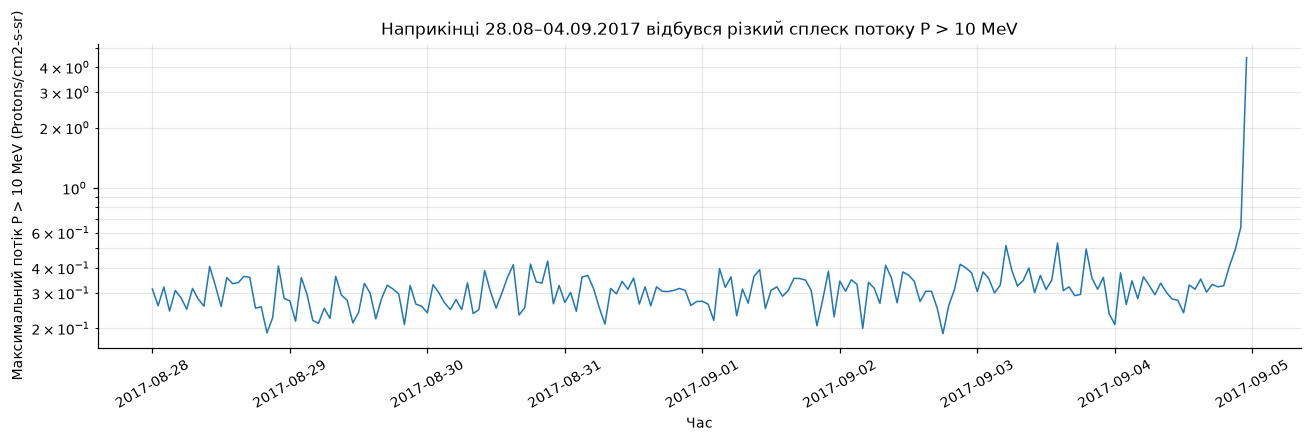

In [25]:
plt.figure(figsize=(12, 4))

plt.plot(
    вікно["ts"],
    вікно[СТОВПЕЦЬ],
    linewidth=1
)

plt.yscale("log")
plt.xlabel("Час")
plt.ylabel("Максимальний потік P > 10 MeV (Protons/cm2-s-sr)")
plt.title(
    "Наприкінці 28.08–04.09.2017 відбувся різкий сплеск потоку P > 10 MeV"
)
plt.xticks(rotation=30)
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

**Відповідь 6.2:** Я обрав лінійний графік часового ряду з логарифмічною шкалою по осі Y. Лінійний графік найкраще показує зміну потоку в часі, а логарифмічна шкала дає змогу одночасно побачити звичайні невеликі значення та дуже великий сплеск наприкінці періоду. На попередньому графіку 1 цей сплеск виглядав непропорційно великим і приховував деталі, тоді як графік 2 показував ширший період і подальший розвиток події. Для вибраного короткого періоду найінформативнішим є графік із логарифмічною шкалою, на якому видно поступові коливання потоку та різке зростання 4 вересня.

---
# Етап 7. Три спостереження та ваше питання

### Завдання 7.1
Запишіть **три спостереження** про ці дані, які ви зробили під час роботи.

Спостереження — це твердження, яке спирається на конкретне число або графік з вашого
ноутбука. Не «дані цікаві», а, наприклад, «максимальне значення потоку у 2000 разів
більше за медіанне, і всі такі години припадають на одні й ті самі три доби».

Для кожного вкажіть, **де саме** у вашій роботі його видно.

**Спостереження 1:** На графіку 4.2, якщо змінювати дні спостереження, можна помітити, що найчастіше найбільша концентрація електронів по E>2 буде у проміжку між 17 та 22 годинами вечора.

**Спостереження 2:** (5.1) Більшість годин має відносно невеликий потік E>2.0 MeV, але окремі години характеризуються значно більшими значеннями, через що розподіл має довгий правий хвіст. При спробі побудувати гістограму від логарифму, він стискає великі значення й розтягує область малих значень, тому стає помітнішою структура даних і розподіл уже не виглядає зосередженим лише біля нуля.

**Спостереження 3:** (5.4) За діаграмою можна побачити, що більшість часу спостерігається тиха активність (68.4%), активні та дуже активні групи були серед 28.5% та 3.2% записів відповідно.


### Завдання 7.2 — ваше індивідуальне питання
Дайте відповідь на додаткове питання зі свого завдання. Відповідь має спиратися
на обчислення: наведіть код і результат, а потім сформулюйте висновок словами.

Питання: Порівняйте медіану вашого потоку за перший і за другий тиждень спостережень. У скільки разів вони відрізняються?

In [26]:
aggr_cols = [
    "ts",
    "E>2"
]

A_weekly_median = (
    A[aggr_cols]
     .set_index("ts")
     .sort_index()
     .resample("1W")
     .agg(["median"])
)

display(A_weekly_median.head())

,E>2
,median
ts,
2017-09-03,452.0
2017-09-10,6790.0
2017-09-17,3590.0
2017-09-24,27250.0


**Відповідь 7.2:**  знайшовши медіани по моєму параметру (E>2) по всіх тижнях, можна побачити, що за перший тиждень медіанне значення було найменшим за весь період спостережень, збільшившись майже в 15 разів у другому тижні. У третьому тижні медіана була вдвічі меншою, потім здобувши найбільше значення під час спостережень четвертого тяжня, збільшившись майже в 7.6 разів порівняно з третім.

---
# Етап 8. Декларація про використання інструментів штучного інтелекту

Користуватися мовними моделями під час виконання цієї роботи **дозволено**. Це
нормальна інженерна практика, і курс про штучний інтелект не має підстав її забороняти.

Обов'язковою є прозорість: ви вказуєте, де саме і як скористалися інструментом —
так само, як у науковій статті вказують використане програмне забезпечення.
**Задекларована допомога порушенням не є.**

Порушенням є інше: здати роботу, яку ви не можете пояснити. На захисті вас попросять
показати конкретний рядок вашого коду, пояснити, чому він саме такий, і внести в нього
невелику зміну на місці. Якщо код згенеровано, але ви його розумієте — робота
зарахована. Якщо не розумієте — не зарахована, незалежно від того, хто його написав.

### Завдання 8.1
Заповніть словник. Для кожного етапу оберіть одне з формулювань:

* `'ні'` — інструментами ШІ не користувався;
* `'синтаксис'` — питав про назву функції або синтаксис, код писав сам;
* `'код, перевірено'` — код згенеровано, я його прочитав, перевірив і розумію;
* `'текст, перероблено'` — згенеровано чернетку тексту, яку я переписав по суті;
* `'текст, як є'` — згенерований текст залишено майже без змін.

Останній варіант не заборонений, але прямо впливає на оцінку: бали ставляться
за висновки, а не за наявність абзацу.

In [27]:
ІНСТРУМЕНТИ_ШІ = 'ChatGPT'     # напр. 'ChatGPT' або 'не використовував'

ДЕКЛАРАЦІЯ = {
    'етапи 1–2, читання файлу та розбір таблиць': 'код, перевірено',
    'етап 3, паспорт даних і дивні значення':     'код, перевірено',
    'етап 4, об’єднання таблиць':                 'код, перевірено',
    'етап 5, побудова графіків':                  'код, перевірено',
    'етап 5, формулювання висновків':             'код, перевірено',
    'етапи 6–7, порівняння графіків і спостереження': 'ні',
}

# Що саме ви перевірили за згенерованим кодом чи текстом — конкретно:
# які числа звірили, що переписали, де знайшли помилку.
ЩО_ПЕРЕВІРЕНО = 'Перевіряв логіку, ознайомлювався з використаними функціями. Звірював та за потреби змінював стовпці, до яких звертався, та підправляв різну описову інформацію у графів. Прибирав зайвий код з повторним оголошенням змінних та імпортами.'

# True означає: я можу пояснити кожен рядок свого коду, відтворити будь-який
# результат цієї роботи та внести зміни в код на вимогу під час захисту.
ПІДТВЕРДЖУЮ = True

In [28]:
# --- перевірка повноти декларації: клітинку не редагувати --------------------
ДОЗВОЛЕНІ = {'ні', 'синтаксис', 'код, перевірено', 'текст, перероблено', 'текст, як є'}

assert ІНСТРУМЕНТИ_ШІ.strip(), 'Вкажіть інструменти або напишіть «не використовував»'
порожні = [k for k, v in ДЕКЛАРАЦІЯ.items() if not str(v).strip()]
assert not порожні, 'Не заповнено пункти декларації: %s' % '; '.join(порожні)
чужі = {v for v in ДЕКЛАРАЦІЯ.values() if v not in ДОЗВОЛЕНІ}
assert not чужі, 'Недопустимі значення: %s. Оберіть з переліку вище.' % ', '.join(sorted(чужі))
assert len(ЩО_ПЕРЕВІРЕНО.strip()) >= 120, ('Опишіть конкретніше, що саме ви перевірили '
                                           '(зараз %d символів, потрібно щонайменше 120)'
                                           % len(ЩО_ПЕРЕВІРЕНО.strip()))
assert ПІДТВЕРДЖУЮ is True, 'Підтвердьте, що можете пояснити власний код на захисті'

print('ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ')
print('=' * 78)
print('%-46s %s' % ('автор:', ПІБ))
print('%-46s %s' % ('інструменти:', ІНСТРУМЕНТИ_ШІ))
print('-' * 78)
for k, v in ДЕКЛАРАЦІЯ.items():
    print('%-46s %s' % (k + ':', v))
print('-' * 78)
print('перевірено автором:')
print(ЩО_ПЕРЕВІРЕНО)
print('=' * 78)
print('Автор підтверджує, що може пояснити кожен рядок коду під час захисту.')

ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ
автор:                                         Мурашко Владислав Сергійович
інструменти:                                   ChatGPT
------------------------------------------------------------------------------
етапи 1–2, читання файлу та розбір таблиць:    код, перевірено
етап 3, паспорт даних і дивні значення:        код, перевірено
етап 4, об’єднання таблиць:                    код, перевірено
етап 5, побудова графіків:                     код, перевірено
етап 5, формулювання висновків:                код, перевірено
етапи 6–7, порівняння графіків і спостереження: ні
------------------------------------------------------------------------------
перевірено автором:
Перевіряв логіку, ознайомлювався з використаними функціями. Звірював та за потреби змінював стовпці, до яких звертався, та підправляв різну описову інформацію у графів. Прибирав зайвий код з повторним оголошенням змінних та імпортами.
Автор підтверджує, що може пояснити кожен рядо

---
# Крок 9. Збереження результату та фінальна самоперевірка

Об'єднана таблиця знадобиться вам у лабораторних роботах № 3 і № 4 — збережіть її
й не втрачайте до кінця семестру.

In [29]:
M.to_csv('master_hourly.csv', index=False)
print('збережено:', M.shape)

збережено: (601, 21)


In [30]:
# --- фінальна самоперевірка --------------------------------------------------
перевірки = {
    'ПІБ і варіант заповнено':        bool(ПІБ) and bool(ВАРІАНТ),
    'таблиця A (7200 рядків)':        len(A) == 7200,
    'таблиця B (25 рядків)':          len(B) == 25,
    'таблиця C (601 рядок)':          len(C) == 601,
    'таблиці об’єднано':              M is not None and 590 <= len(M) <= 605,
    'стовпець «група» є':             'група' in M.columns,
    'усі дати у 2017 році':           int(pd.to_datetime(M['ts']).dt.year.min()) == 2017,
    'декларацію заповнено':           bool(ІНСТРУМЕНТИ_ШІ.strip()) and ПІДТВЕРДЖУЮ is True,
}
for k, v in перевірки.items():
    print(('OK   ' if v else 'НЕ ОК') + '  ' + k)

if all(перевірки.values()):
    print('\nТехнічна частина роботи виконана.')
    print('Тепер переконайтеся, що заповнені ВСІ клітинки з відповідями та висновками,')
    print('і виконайте Kernel → Restart & Run All перед здачею.')

OK     ПІБ і варіант заповнено
OK     таблиця A (7200 рядків)
OK     таблиця B (25 рядків)
OK     таблиця C (601 рядок)
OK     таблиці об’єднано
OK     стовпець «група» є
OK     усі дати у 2017 році
OK     декларацію заповнено

Технічна частина роботи виконана.
Тепер переконайтеся, що заповнені ВСІ клітинки з відповідями та висновками,
і виконайте Kernel → Restart & Run All перед здачею.
